# 04 - Critical evaluation (Step 4)

The research question: **how much do random-split scores overstate real-world (future)
performance, and do AutoML tools protect against leakage and temporal drift, or do they fall for
them?**

Step 4 answers it in four parts, each with its own script and write-up:

| part | script | write-up |
|---|---|---|
| A. leakage: add a label proxy and a time stamp on purpose | `scripts/run_leakage.py` | `reports/leakage.md` |
| B. random vs future split, bias slices, drift, challenge set | `scripts/run_eval_bias.py` | `reports/temporal_bias.md` |
| C. SHAP, cross-tool agreement, calibration, cost threshold | `scripts/run_explain.py` | `reports/explainability.md` |
| synthesis | `scripts/run_critical_eval.py` | `reports/critical_eval.md`, `reports/limitations.md` |

**Hardware.** The Step 4 leakage reruns, bias fits and SHAP fits ran on a 4-core / 15 GB Linux cloud
VM, not on the laptop that ran Steps 2-3. Every with/without-leak comparison was run on the VM with
the same settings, and no time is compared across the two machines. The leakage reruns used a shorter
budget than Step 3 (printed below), so their AutoML scores are not the Step 3 scores.

**Test-set discipline.** No model, early-stopping point or threshold was chosen on `test_random` or
`test_future`. Thresholds come from out-of-fold scores on `train`.

This notebook only reads the saved tables, figures and write-ups. It trains nothing.

In [1]:
# Make the project root importable when the notebook is opened from notebooks/.
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import json

import pandas as pd
from IPython.display import Image, Markdown, display

import config

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)


def table(stem: str) -> pd.DataFrame:
    """Read a generated table from reports/tables (the _quick copy in quick mode)."""
    return pd.read_csv(config.TABLES / f"{stem}{config.RUN_SUFFIX}.csv")


def figure(stem: str) -> None:
    """Show a generated figure from reports/figures."""
    display(Image(filename=str(config.FIGURES / f"{stem}{config.RUN_SUFFIX}.png")))


def section(report: str, heading: str) -> None:
    """Show one section of a generated write-up in reports/, from `heading` to the next heading
    at the same or a higher level. A "# " title shows only its intro, up to the first "## "."""
    lines = (config.REPORTS / f"{report}{config.RUN_SUFFIX}.md").read_text(encoding="utf-8").splitlines()
    start = next(i for i, line in enumerate(lines) if line.startswith(heading))
    level = max(len(heading) - len(heading.lstrip("#")), 2)
    end = next((j for j in range(start + 1, len(lines))
                if lines[j].startswith("#") and len(lines[j]) - len(lines[j].lstrip("#")) <= level),
               len(lines))
    display(Markdown("\n".join(lines[start:end])))


print(f"quick={config.QUICK}")
print("Step 4 leakage budget per AutoML run (s):", config.LEAKAGE_BUDGET_S,
      "| Step 3 budget (s):", config.AUTOML_BUDGET_S)

quick=False
Step 4 leakage budget per AutoML run (s): 600 | Step 3 budget (s): 1200


## The answer in short

The synthesis write-up states the machines used, the thresholds, and the five main findings:

In [3]:
section("critical_eval", "# Critical evaluation")
section("critical_eval", "## The answer in short")

# Critical evaluation: how far do random-split scores overstate real-world performance, and does AutoML protect against leakage and drift?

Generated by `scripts/run_critical_eval.py` (`src/critical_eval_writeup.py`) from `reports/tables/random_vs_future.csv`, `reports/tables/precision_both_sets.csv`, `reports/tables/challenge.csv`, `reports/tables/leakage.csv`, `reports/tables/gap_vs_tuned.csv`, `reports/tables/automl_self_estimate.csv`, `reports/tables/cv_comparison.csv`, `reports/tables/drift.csv`, `reports/tables/gap_adversarial.csv`, `reports/tables/class_weight.csv`, `reports/tables/calibration.csv` and `eval_bias_facts.json`. Nothing here is typed by hand; the detail behind each section is in [`leakage.md`](leakage.md), [`temporal_bias.md`](temporal_bias.md) and [`explainability.md`](explainability.md), and the threats to validity are in [`limitations.md`](limitations.md).

**Machine.** Steps 2-3 (the tuning searches and the 1200 s AutoML runs, and the saved models scored here) ran on a 16-core Intel Core Ultra 9 285H laptop (63 GB RAM, Windows) with 16 threads. Step 4 ran on a cloud VM: Intel(R) Xeon(R) Processor @ 2.10GHz, 4 logical CPUs, 15.7 GB RAM, Linux 6.18.44-fc-v185; the leakage runs used 4 threads (the part B and C fits 2, because those two jobs shared the machine). Every with/without comparison inside Step 4 was run on the VM with the same settings. No wall-clock time is compared across the two machines, and the AutoML scores at the Step 4 budget are not the Step 3 scores (fewer cores search fewer configurations in the same time). The challenge-set scores (sections 1, 2 and the verdict) were computed on a 16-CPU Windows machine (the laptop), which holds every saved Step 2-3 model; scoring fits nothing, so the hardware does not change those numbers.

**Test-set discipline.** No model, configuration, early-stopping point or threshold was chosen on test_random or test_future. The thresholds used below are 0.5, the 1%-FPR threshold set on TRAIN out-of-fold scores (`train_oof_1pct_fpr`) and the cost-sensitive deployment threshold in `models/threshold.json` (also set on TRAIN out-of-fold scores). CIs are 95%: bootstrap (1000 resamples, seed 42) or Wilson for rates.


## The answer in short

1. **Ranking metrics barely move for the tree models.** From test_random to test_future the tuned LightGBM goes from AUC 0.9991 to 0.9981 (gap 0.0010 [0.0007, 0.0014]) and from TPR@1%FPR 98.7% to 97.6% (gap +1.07 pp [+0.67 pp, +1.46 pp]). The AUC gaps of all 7 tree models lie between 0.0010 and 0.0014; only LogReg, which cannot cap out-of-range feature values, loses much more (0.0632 AUC). By AUC alone, the random split overstates the tuned model's real-world performance only slightly.
2. **The overstatement is in the operating point and the base rate, which AUC hides.** At the threshold fixed on train (t = 0.5666) the false-positive rate rises from 0.95% on test_random to 1.23% on test_future (+29% relative). On the 50/50 test sets precision is 99.0% / 98.8%; at a realistic 1% malware prevalence it is 51.2% [47.6%, 54.7%] on test_random and 44.7% [41.6%, 47.8%] on test_future, i.e. 121 false alarms per 10,000 files scanned (random split: 94). Reading the 50/50 test_random as 1%-prevalence traffic changes precision by -47.87 pp; moving from test_random to test_future at that prevalence changes it by -6.50 pp: the 50/50 test mix is the larger source of optimism.
3. **The hard tail is invisible to both test sets.** On the 814 Win64 challenge-set files (malware that antivirus engines missed when first seen) the tuned model detects 53.7% [50.3%, 57.1%] at the same threshold, against 97.9% of ordinary test_future malware.
4. **No AutoML tool protects against the label leak.** With `detection_ratio` added, 4 of 4 models (tuned LightGBM and the three AutoML tools) ranked it first, by their own importance or by SHAP, and scored test_future AUC 0.9999 to 1.0000; 0 log lines named the column and 0 tools dropped it. The future split does not expose this leak either: a post-hoc label proxy is just as available (and perfect) in later weeks.
5. **AutoML does not protect against drift.** None of the 3 AutoML tools has a smaller AUC gap than the tuned LightGBM; a larger one: H2O AutoML (+0.0004 [+0.0002, +0.0007]) (paired bootstrap CI of the gap difference), `reports/tables/gap_vs_tuned.csv`. Every tool validated on a random split of `train` (the same weeks as its training rows): its own validation AUC was 0.9952 to 0.9994 on the clean runs, against test_future 0.9922 to 0.9980, and 1.0000 with the leak: a near-perfect score that no tool questioned.


## 1. Random split vs future weeks

Every model scored on both test sets. `roc_auc_gap` is test_random minus test_future, with a paired
bootstrap CI. A positive gap means the random split overstates performance. The tree models' gaps
are small; the linear model's is much larger.

In [4]:
rvf = table("random_vs_future")
rvf[["model", "kind", "test_random_roc_auc", "test_future_roc_auc", "roc_auc_gap", "roc_auc_gap_ci_low",
     "roc_auc_gap_ci_high", "tpr_at_1pct_fpr_gap", "fpr_gap"]]

,model,kind,test_random_roc_auc,test_future_roc_auc,roc_auc_gap,roc_auc_gap_ci_low,roc_auc_gap_ci_high,tpr_at_1pct_fpr_gap,fpr_gap
0,lgbm_default,baseline,0.997816,0.996711,0.001105,0.000639,0.001580,0.013900,-0.006800
1,logreg,baseline,0.992858,0.929691,0.063167,0.059969,0.066444,0.097390,-0.007700
2,grid,tuned,0.999057,0.998048,0.001009,0.000652,0.001384,0.011849,-0.004200
3,random,tuned,0.999012,0.997959,0.001053,0.000692,0.001415,0.009849,-0.004450
4,optuna,tuned,0.999115,0.998105,0.001010,0.000653,0.001360,0.010699,-0.002850
5,flaml,automl,0.998642,0.997571,0.001071,0.000685,0.001489,0.013949,-0.006950
6,autogluon,automl,0.999076,0.998044,0.001032,0.000671,0.001386,0.009649,-0.004200
7,h2o,automl,0.998437,0.997007,0.001430,0.000961,0.001930,0.012549,-0.009351


**Which cross-validation predicts the future better?** A normal stratified CV mixes all weeks, like
`test_random`. A forward (week-blocked) CV always validates on later weeks than it trains on. The
`*_abs_error_vs_future` columns say how far each estimate is from the real test_future score.

In [5]:
table("cv_comparison")[["estimate", "n_folds", "train_rows_mean", "roc_auc", "tpr_at_1pct_fpr",
                        "roc_auc_abs_error_vs_future", "tpr_at_1pct_fpr_abs_error_vs_future"]]

,estimate,n_folds,train_rows_mean,roc_auc,tpr_at_1pct_fpr,roc_auc_abs_error_vs_future,tpr_at_1pct_fpr_abs_error_vs_future
0,stratified_3fold_cv,3,106666.666667,0.998778,0.983199,0.000673,0.007396
1,forward_cv_4fold,4,83076.250000,0.997515,0.966054,0.000590,0.009750
2,test_random,0,NaN,0.999115,0.986503,0.001010,0.010699
3,test_future,0,NaN,0.998105,0.975804,0.000000,0.000000
4,"step2_tuning_cv (60k subset, early stopping)",3,40000.000000,0.997774,NaN,0.000331,NaN


**Why is the gap so small for trees?** An adversarial classifier can tell the training weeks from the
future weeks easily (compare the control row with the second row below), so the features *do*
shift, mostly in date-like columns. The tuned LightGBM leans little on the most-drifting column, and
a tree cannot extrapolate: a value beyond the training range lands in the same leaf as the largest
training value. A linear model keeps adding weight times value, so out-of-range values move its score
much more. `temporal_bias.md`, section 3, has the full evidence.

In [6]:
table("gap_adversarial")

,comparison,auc,n_past,n_future
0,train split vs same weeks 0-51 (control),0.497323,20000,20000
1,train split vs future weeks 52-63,0.938320,20000,20000


## 2. The base rate: precision at realistic malware prevalence

The test sets are 50/50. Real traffic is mostly benign. Precision at prevalence pi is
pi*TPR / (pi*TPR + (1-pi)*FPR), with TPR and FPR measured on each test set at a threshold fixed on
`train`. Below: every model at 1% prevalence.

In [7]:
precision = table("precision_both_sets")
at_1pct = precision[precision["prevalence"] == 0.01]
at_1pct.pivot_table(index=["model", "threshold_name"], columns="test_set",
                    values=["precision", "false_alarms_per_10k"])

false_alarms_per_10k               precision            
test_set                                 test_future test_random test_future test_random
model        threshold_name                                                             
autogluon    0.5                          143.076461  101.495299    0.406855    0.492880
flaml        0.5                          194.564185  125.755151    0.334287    0.438406
grid         0.5                          139.610942   98.029606    0.412365    0.501388
h2o          0.5                          250.012502  157.441488    0.281476    0.384024
lgbm_default 0.5                          239.615942  172.294459    0.288797    0.361482
             train_oof_1pct_fpr           143.076461   97.534507    0.401684    0.497181
logreg       0.5                          387.643146  311.417283    0.185050    0.237102
             train_oof_1pct_fpr            94.064110   81.196239    0.463921    0.526119
optuna       0.5                          130.699605  102.485497    0.428748    0.490593
             deployment                   735.680352  604.020804    0.119141    0.141712
             train_oof_1pct_fpr           121.293194   94.068814    0.446689    0.511709
random       0.5                          149.512427  105.456091    0.396099    0.482973

## 3. The challenge set: malware that antivirus engines missed at first

EMBER2024's challenge set holds files that were not detected when first seen. All are malicious, so
the only metric is the detection rate (with a Wilson CI). Compare it with the same model's TPR on
ordinary test_future malware at the same threshold.

In [8]:
challenge = table("challenge")
challenge[challenge["subset"] == "all Win64 challenge"][
    ["model", "threshold_name", "n", "detection_rate", "ci_low", "ci_high", "test_future_tpr_same_threshold"]]

,model,threshold_name,n,detection_rate,ci_low,ci_high,test_future_tpr_same_threshold
0,lgbm_default,0.5,814,0.466830,0.432794,0.501179,0.973004
3,lgbm_default,train_oof_1pct_fpr,814,0.332924,0.301401,0.366016,0.960556
6,grid,0.5,814,0.557740,0.523429,0.591508,0.979703
9,random,0.5,814,0.545455,0.511115,0.579367,0.980653
12,optuna,0.5,814,0.556511,0.522197,0.590295,0.980953
15,optuna,train_oof_1pct_fpr,814,0.536855,0.502507,0.570857,0.979203
18,optuna,deployment,814,0.798526,0.769598,0.824649,0.995051
21,logreg,0.5,814,0.519656,0.485322,0.553805,0.880218
24,logreg,train_oof_1pct_fpr,814,0.239558,0.211504,0.270058,0.814028
27,flaml,0.5,814,0.506143,0.471849,0.540379,0.977003


## 4. Leakage: does any tool notice a leaked column?

Each model was rerun with one extra column: `detection_ratio` (a near-copy of the label) or the raw
`first_submission_date` (a time stamp). `delta_*` is the change against the same model's clean run.
`leak_rank_native` / `leak_rank_shap` is where the leaked column ranked in importance (1 = top), and
`n_lines_mentioning_leak` counts log lines from the tool that named it. A tool that "protects" would
warn, drop the column, or at least not rank it first.

In [9]:
leak = table("leakage")
leak[["model", "variant", "test_random_roc_auc", "test_future_roc_auc", "delta_test_future_roc_auc",
      "leak_rank_native", "leak_rank_shap", "n_lines_mentioning_leak", "leak_dropped_by_tool",
      "relied_on_leak", "wall_s"]]

,model,variant,test_random_roc_auc,test_future_roc_auc,delta_test_future_roc_auc,leak_rank_native,leak_rank_shap,n_lines_mentioning_leak,leak_dropped_by_tool,relied_on_leak,wall_s
0,lgbm_tuned,clean,0.999115,0.998105,NaN,NaN,NaN,0,NaN,NaN,249.455335
1,lgbm_tuned,leak_detection_ratio,1.000000,1.000000,0.001895,1.0,1.0,0,NaN,True,121.710079
2,lgbm_tuned,leak_first_submission,0.999149,0.998219,0.000113,45.0,28.0,0,NaN,False,253.950178
3,lgbm_tuned,ablate_time_proxies,0.999023,0.997948,-0.000157,NaN,NaN,0,NaN,NaN,236.697260
4,flaml,clean,0.999021,0.997992,NaN,NaN,NaN,0,NaN,NaN,1021.276973
5,flaml,leak_detection_ratio,0.999998,1.000000,0.002008,2.0,1.0,0,False,True,772.086362
6,flaml,leak_first_submission,0.998774,0.997789,-0.000204,1.0,23.0,0,False,False,884.648426
7,autogluon,clean,0.999076,0.998044,NaN,NaN,NaN,0,NaN,NaN,607.931123
8,autogluon,leak_detection_ratio,0.999905,0.999925,0.001881,1.0,1.0,0,False,True,405.566005
9,autogluon,leak_first_submission,0.999086,0.998180,0.000135,3.0,28.0,0,False,False,608.185860


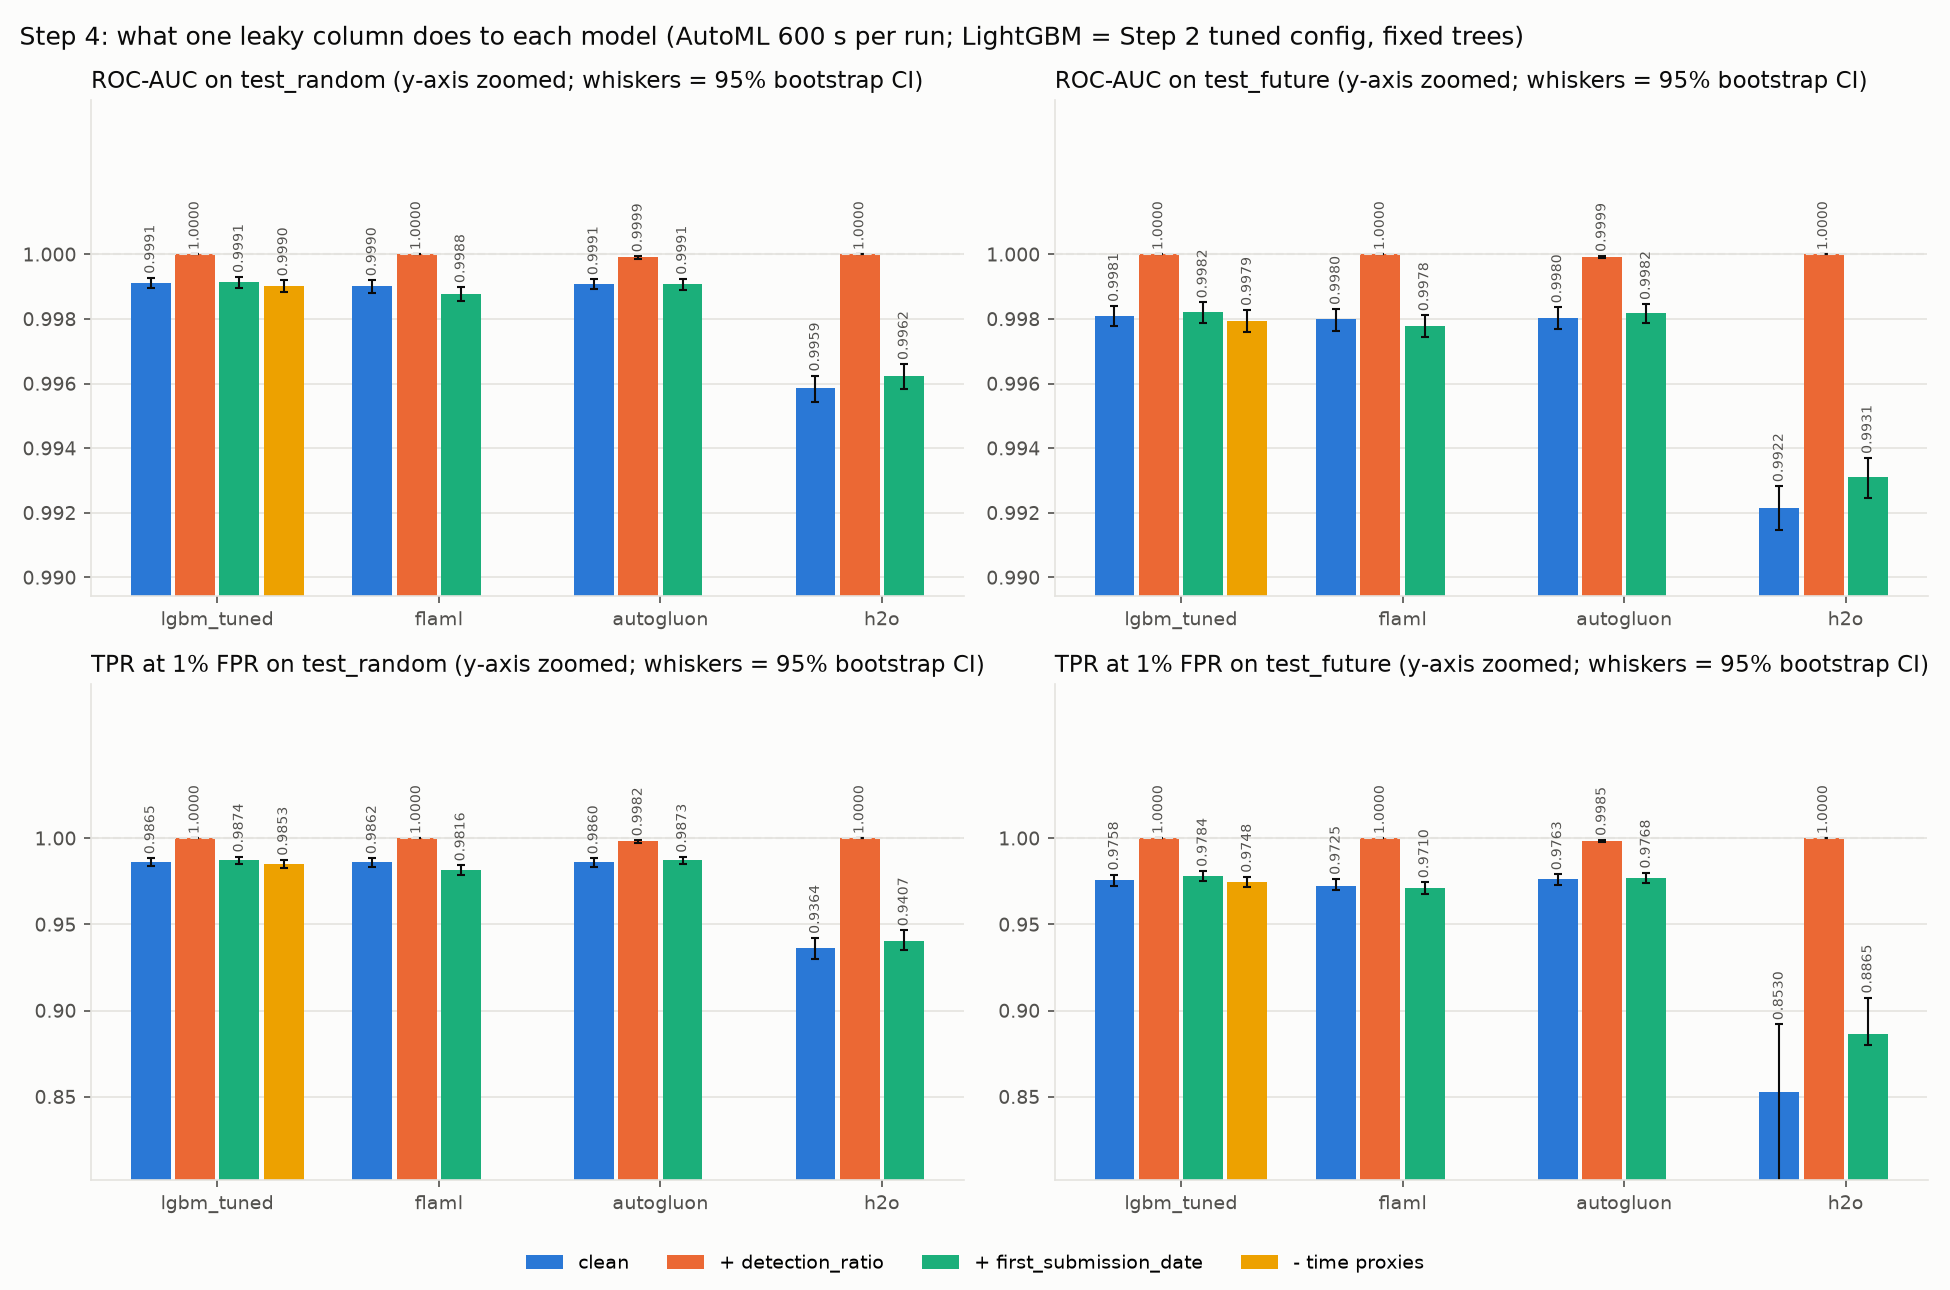

In [10]:
figure("leakage_jump")

The time-proxy ablation row (`ablate_time_proxies`) removes the compile and signing time columns that
are already in `X`. Run times (`wall_s`) are from the 4-core VM; `leakage.md` discusses the AutoML
runs that went past their budget.

## 5. Does AutoML protect against drift?

If an AutoML tool protected against drift, its random-vs-future gap would be smaller than the tuned
LightGBM's. `gap_minus_tuned` is the tool's gap minus the tuned model's gap, with a paired CI.

In [11]:
table("gap_vs_tuned")

,model,kind,metric,gap,tuned_gap,gap_minus_tuned,gap_minus_tuned_ci_low,gap_minus_tuned_ci_high,differs_from_tuned
0,lgbm_default,baseline,roc_auc,0.001105,0.001010,9.548373e-05,-0.000182,0.000353,False
1,lgbm_default,baseline,tpr_at_1pct_fpr,0.013900,0.010699,3.200610e-03,-0.001995,0.007623,False
2,logreg,baseline,roc_auc,0.063167,0.001010,6.215749e-02,0.058963,0.065337,True
3,logreg,baseline,tpr_at_1pct_fpr,0.097390,0.010699,8.669061e-02,0.073650,0.100567,True
4,grid,tuned,roc_auc,0.001009,0.001010,-7.275010e-07,-0.000130,0.000141,False
5,grid,tuned,tpr_at_1pct_fpr,0.011849,0.010699,1.149865e-03,-0.001255,0.003633,False
6,random,tuned,roc_auc,0.001053,0.001010,4.334500e-05,-0.000068,0.000155,False
7,random,tuned,tpr_at_1pct_fpr,0.009849,0.010699,-8.497651e-04,-0.003013,0.001714,False
8,optuna,tuned,roc_auc,0.001010,0.001010,0.000000e+00,0.000000,0.000000,False
9,optuna,tuned,tpr_at_1pct_fpr,0.010699,0.010699,0.000000e+00,0.000000,0.000000,False


Each tool also judged itself on its own validation rows. Those rows come from the same weeks as its
training rows, so the self-estimate cannot see drift:

In [12]:
table("automl_self_estimate")[["tool", "run", "variant", "budget_s", "machine", "own_validation",
                                "own_auc", "test_future_roc_auc", "own_minus_future"]]

,tool,run,variant,budget_s,machine,own_validation,own_auc,test_future_roc_auc,own_minus_future
0,flaml,step3,clean,1200.0,"16 threads, Steps 2-3 laptop",random stratified holdout of train (16000 rows),0.998513,0.997571,0.000942
1,autogluon,step3,clean,1200.0,"16 threads, Steps 2-3 laptop",random holdout of train (2496 rows),0.999404,0.998044,0.001359
2,h2o,step3,clean,1200.0,"16 threads, Steps 2-3 laptop",random validation frame of train (16092 rows),0.998448,0.997007,0.001441
3,flaml,step4_leakage,clean,600.0,"4 threads, 4-CPU Linux VM",random stratified holdout of train (16000 rows),0.995243,0.997992,-0.002750
4,autogluon,step4_leakage,clean,600.0,"4 threads, 4-CPU Linux VM",random holdout of train (2496 rows),0.999404,0.998044,0.001359
5,h2o,step4_leakage,clean,600.0,"4 threads, 4-CPU Linux VM",random validation frame of train (15803 rows),0.995525,0.992159,0.003366
6,flaml,step4_leakage,leak_detection_ratio,600.0,"4 threads, 4-CPU Linux VM",random stratified holdout of train (16000 rows),0.999998,1.000000,-0.000002
7,autogluon,step4_leakage,leak_detection_ratio,600.0,"4 threads, 4-CPU Linux VM",random holdout of train (2496 rows),0.999954,0.999925,0.000029
8,h2o,step4_leakage,leak_detection_ratio,600.0,"4 threads, 4-CPU Linux VM",random validation frame of train (15803 rows),1.000000,1.000000,0.000000
9,flaml,step4_leakage,leak_first_submission,600.0,"4 threads, 4-CPU Linux VM",random stratified holdout of train (16000 rows),0.995298,0.997789,-0.002491


**Drift over the future weeks.** The same tuned configuration trained on three windows and scored
week by week on the future weeks: all past weeks (`expanding`, the saved Step 2 model), only the last
12 weeks (`sliding_12w`), and a random sample of all past weeks with as many rows as the sliding
window (`size_matched`). Sliding vs size-matched separates "recent data" from "less data".

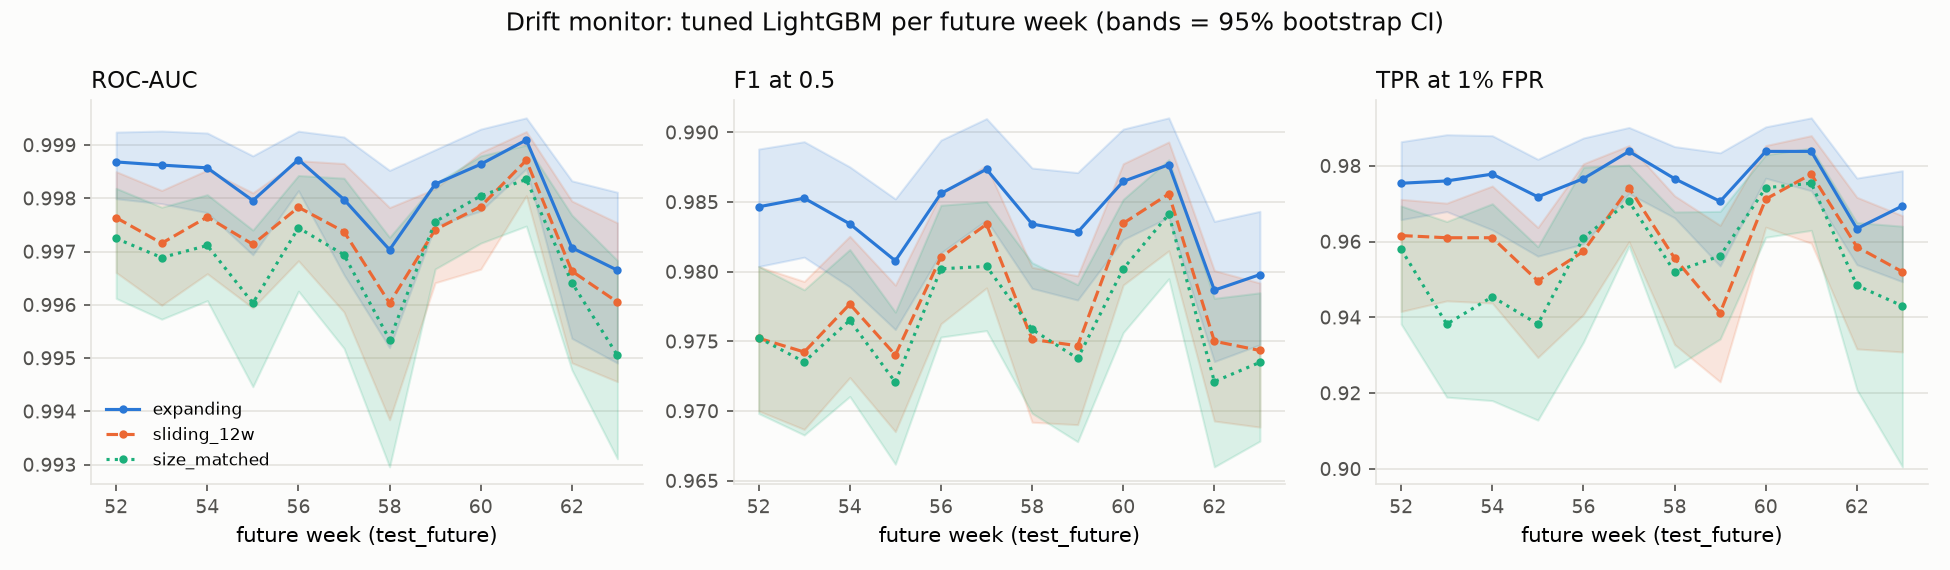

In [13]:
figure("drift")

## 6. Bias slices

Detection rate (TPR) and false-alarm rate (FPR) per slice: week, malware family, file-size quartile,
an entropy proxy, packer, and whether the file is signed.
Slices with too few files are flagged in `bias_slices.csv` (`tpr_too_small`, `fpr_too_small`).

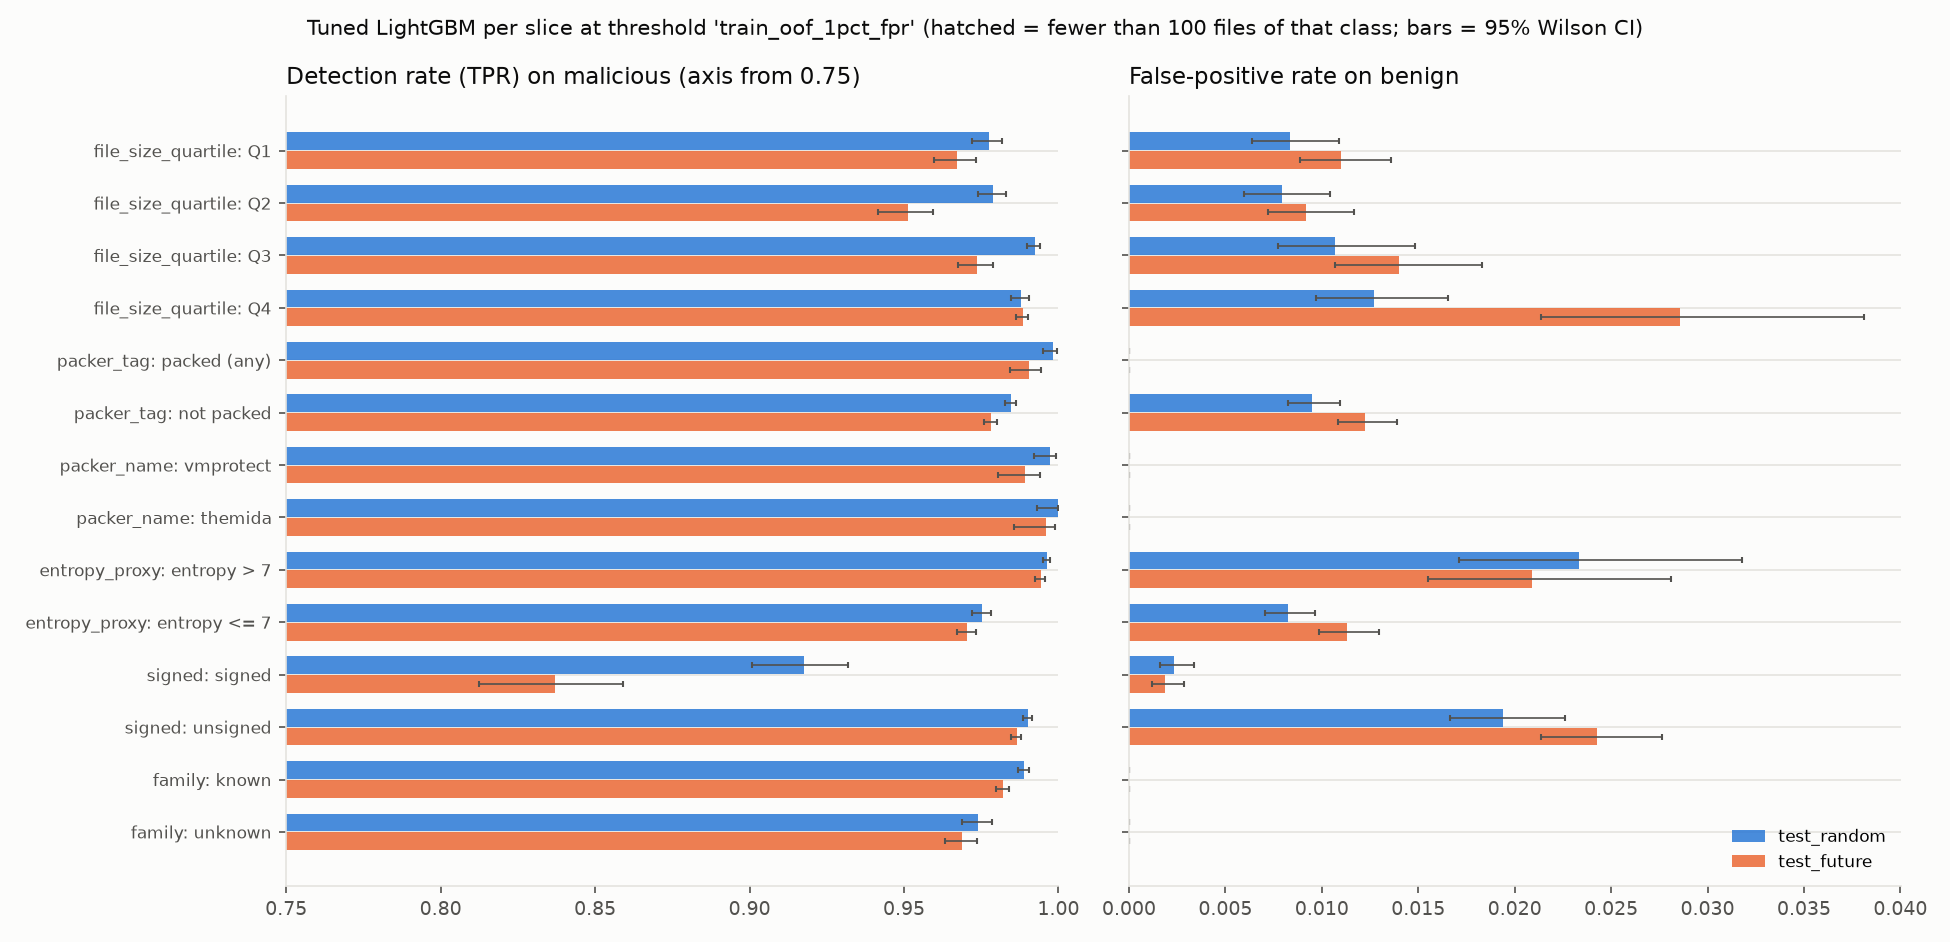

In [14]:
figure("bias_slices")

## 7. What does the model look at? SHAP and cross-tool agreement

TreeSHAP splits each prediction into per-feature contributions. Summed by feature family, it shows
which parts of the PE file matter. Then we check whether the time proxies rank high, and whether the
AutoML winners rely on the same features.

In [15]:
table("shap_family_importance")[["rank", "family", "n_features", "share", "top_feature"]]

,rank,family,n_features,share,top_feature
0,1,strings,177,0.174932,strings: char_'_'_freq
1,2,imports,1282,0.150882,imports: function[hash 989]
2,3,histogram,256,0.127547,histogram: byte_0x00_freq
3,4,header,74,0.111626,header: coff.char.DLL
4,5,datadirectories,34,0.105431,datadirectories: EXPORT.size
5,6,section,224,0.098454,section: n_rx
6,7,byteentropy,256,0.082196,byteentropy: entropy_bin9/byte_hi_nibble0
7,8,authenticode,8,0.067232,authenticode: latest_signing_time
8,9,pefilewarnings,88,0.045163,pefilewarnings: warning[Suspicious flags set f...
9,10,richheader,33,0.019611,richheader: pair[hash 3]


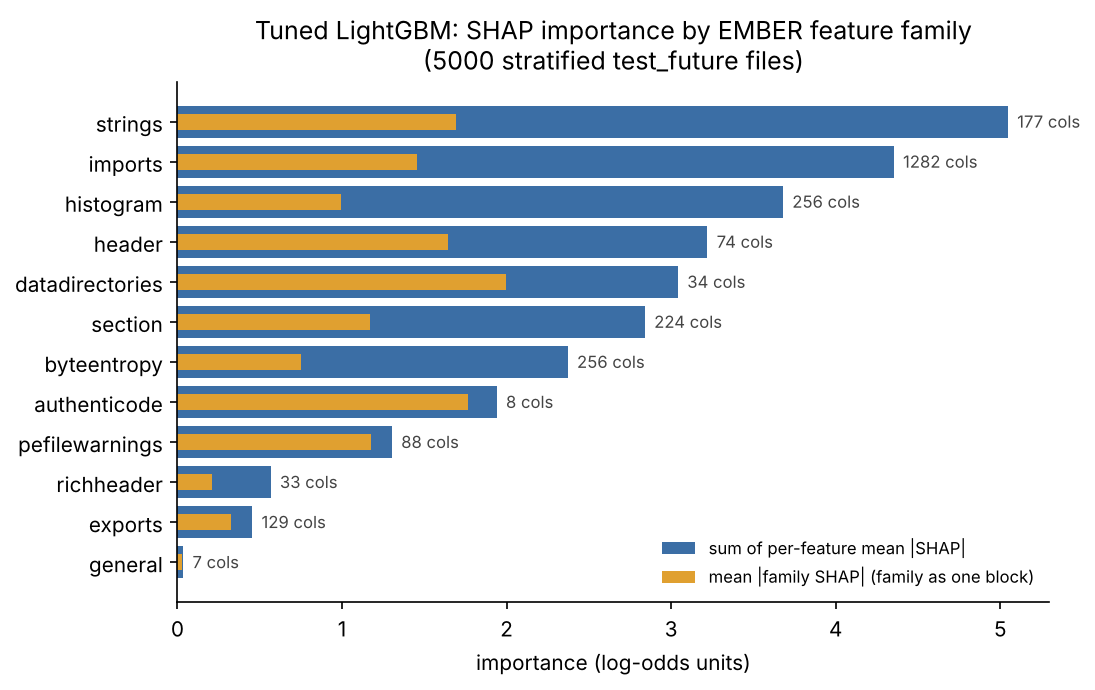

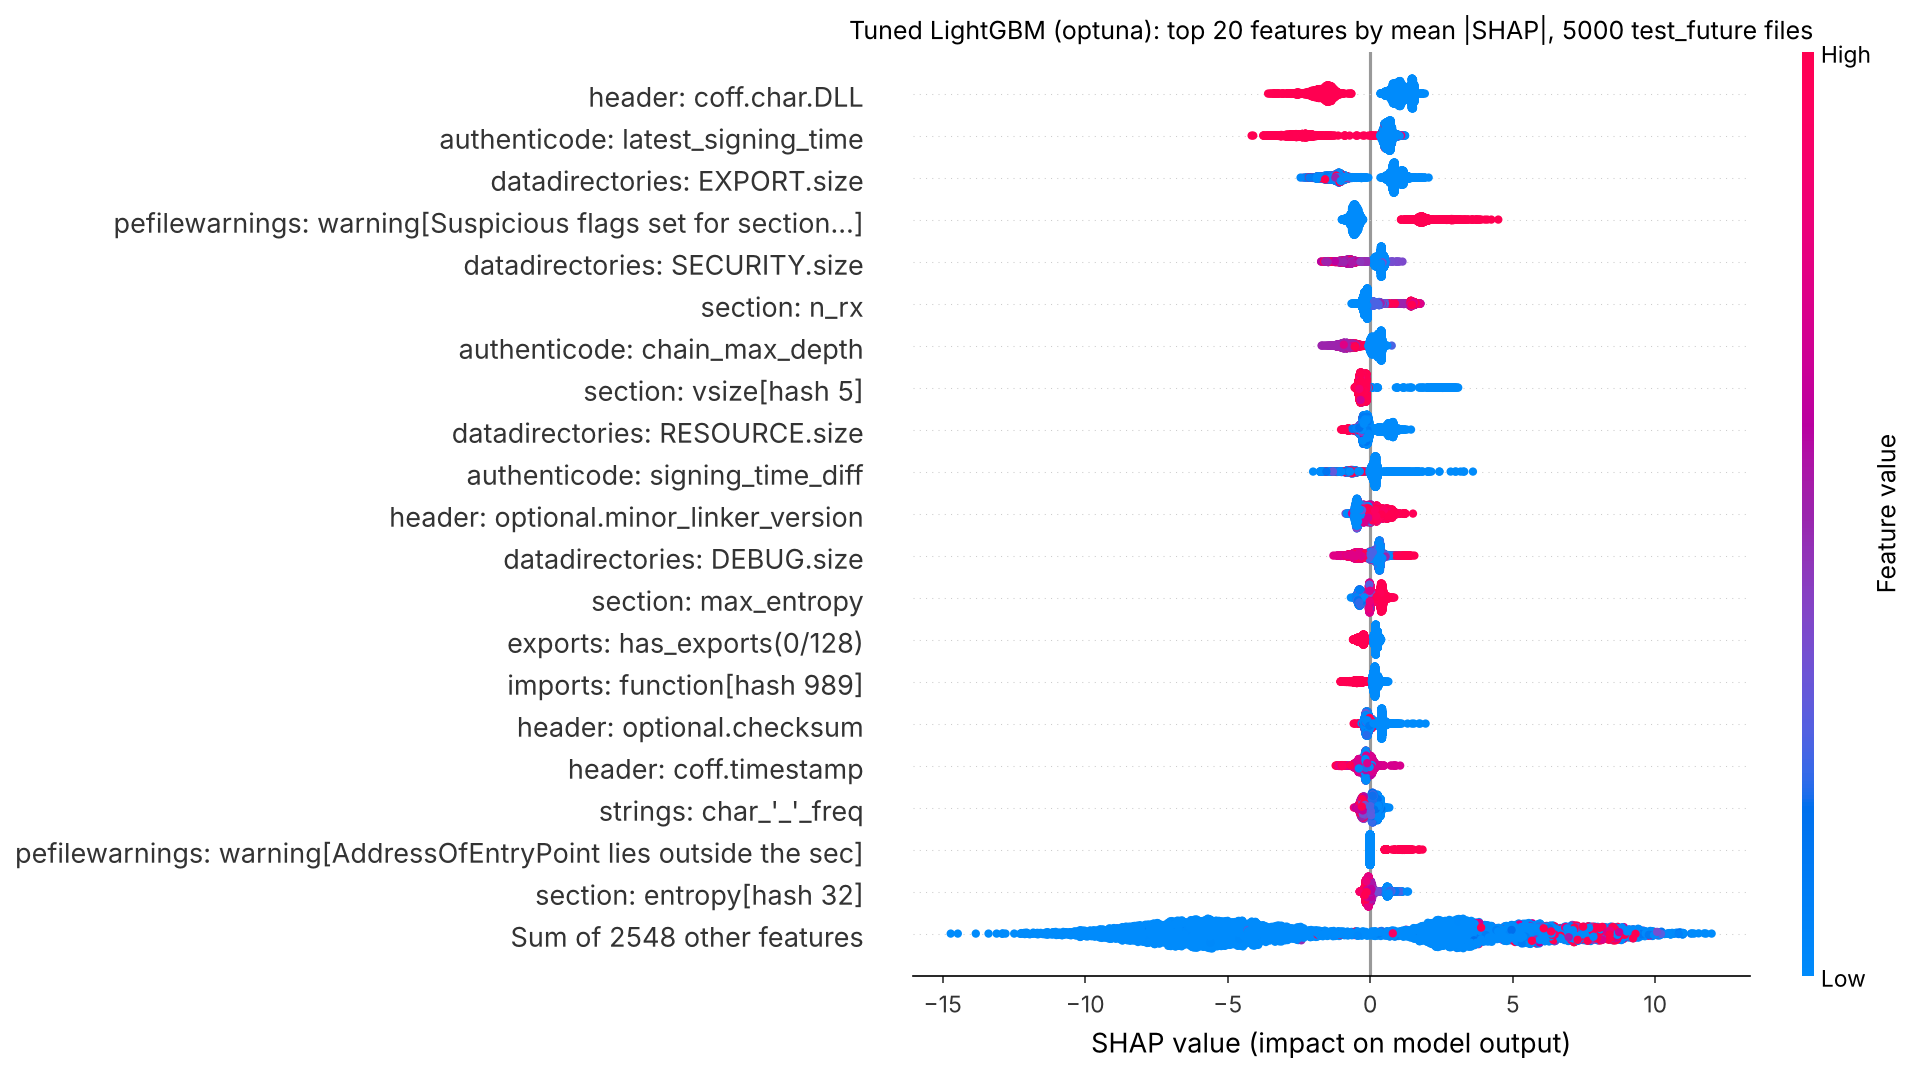

In [16]:
figure("shap_family_bar")
figure("shap_beeswarm")

In [17]:
table("time_proxy_ranks")

,feature,column,label,rank_lgbm_tuned,rank_flaml,rank_autogluon,rank_h2o,importance_lgbm_tuned,importance_flaml,importance_autogluon,importance_h2o
0,header__0,696,header: coff.timestamp,17,32,2268,40,0.218333,0.094788,-0.000001,201.013977
1,authenticode__6,2478,authenticode: latest_signing_time,2,3,4,3,1.120775,0.618773,0.000146,18716.173828
2,authenticode__7,2479,authenticode: signing_time_diff,10,8,2557,21,0.358566,0.232741,-0.000016,393.860352


In [18]:
table("cross_tool_agreement")[["tool_a", "tool_b", "top5_overlap", "top20_overlap", "family_spearman",
                               "top_family_a", "top_family_b"]]

,tool_a,tool_b,top5_overlap,top20_overlap,family_spearman,top_family_a,top_family_b
0,lgbm_tuned,flaml,4,14,0.986014,strings,strings
1,lgbm_tuned,autogluon,3,8,0.811189,strings,imports
2,lgbm_tuned,h2o,2,7,0.321678,strings,exports
3,flaml,autogluon,4,8,0.762238,strings,imports
4,flaml,h2o,3,10,0.328671,strings,exports
5,autogluon,h2o,3,7,0.398601,imports,exports


Three single-file explanations: a caught malware file (TP), a false alarm (FP) and a missed malware
file (FN). Each bar is one feature pushing the score up or down from the average.

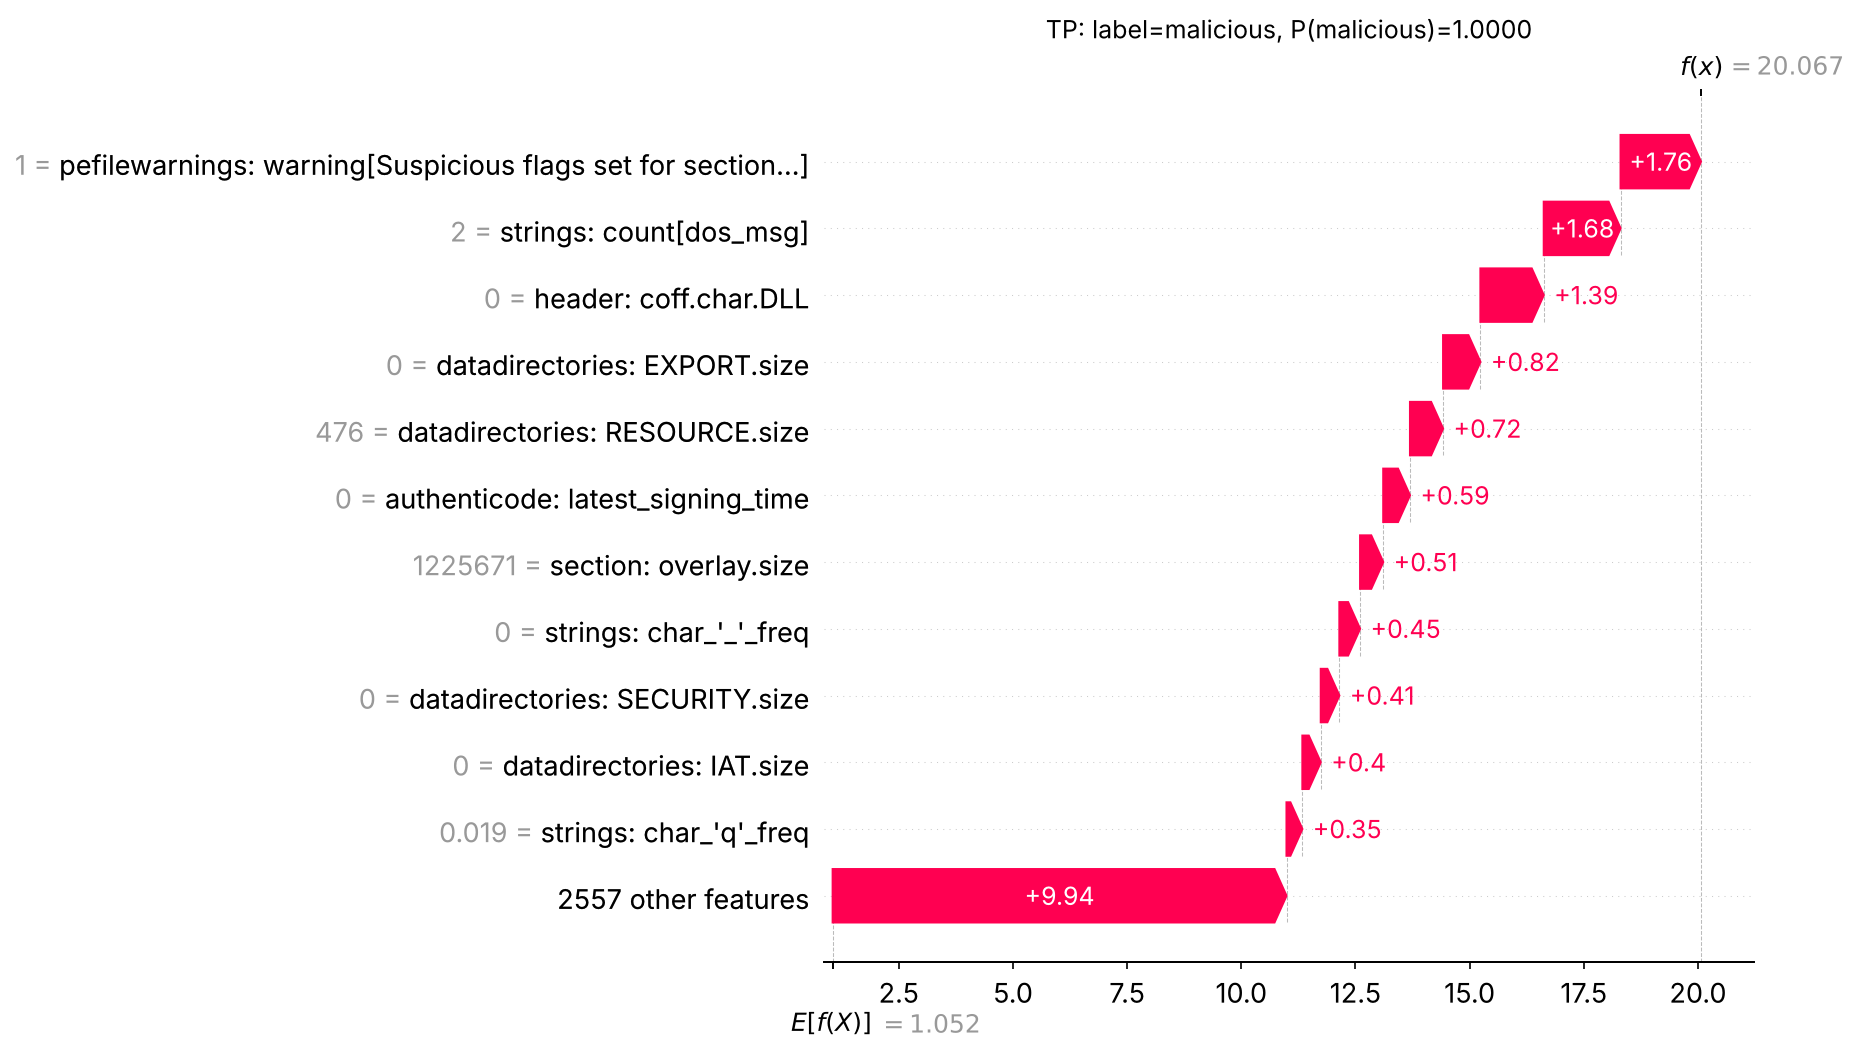

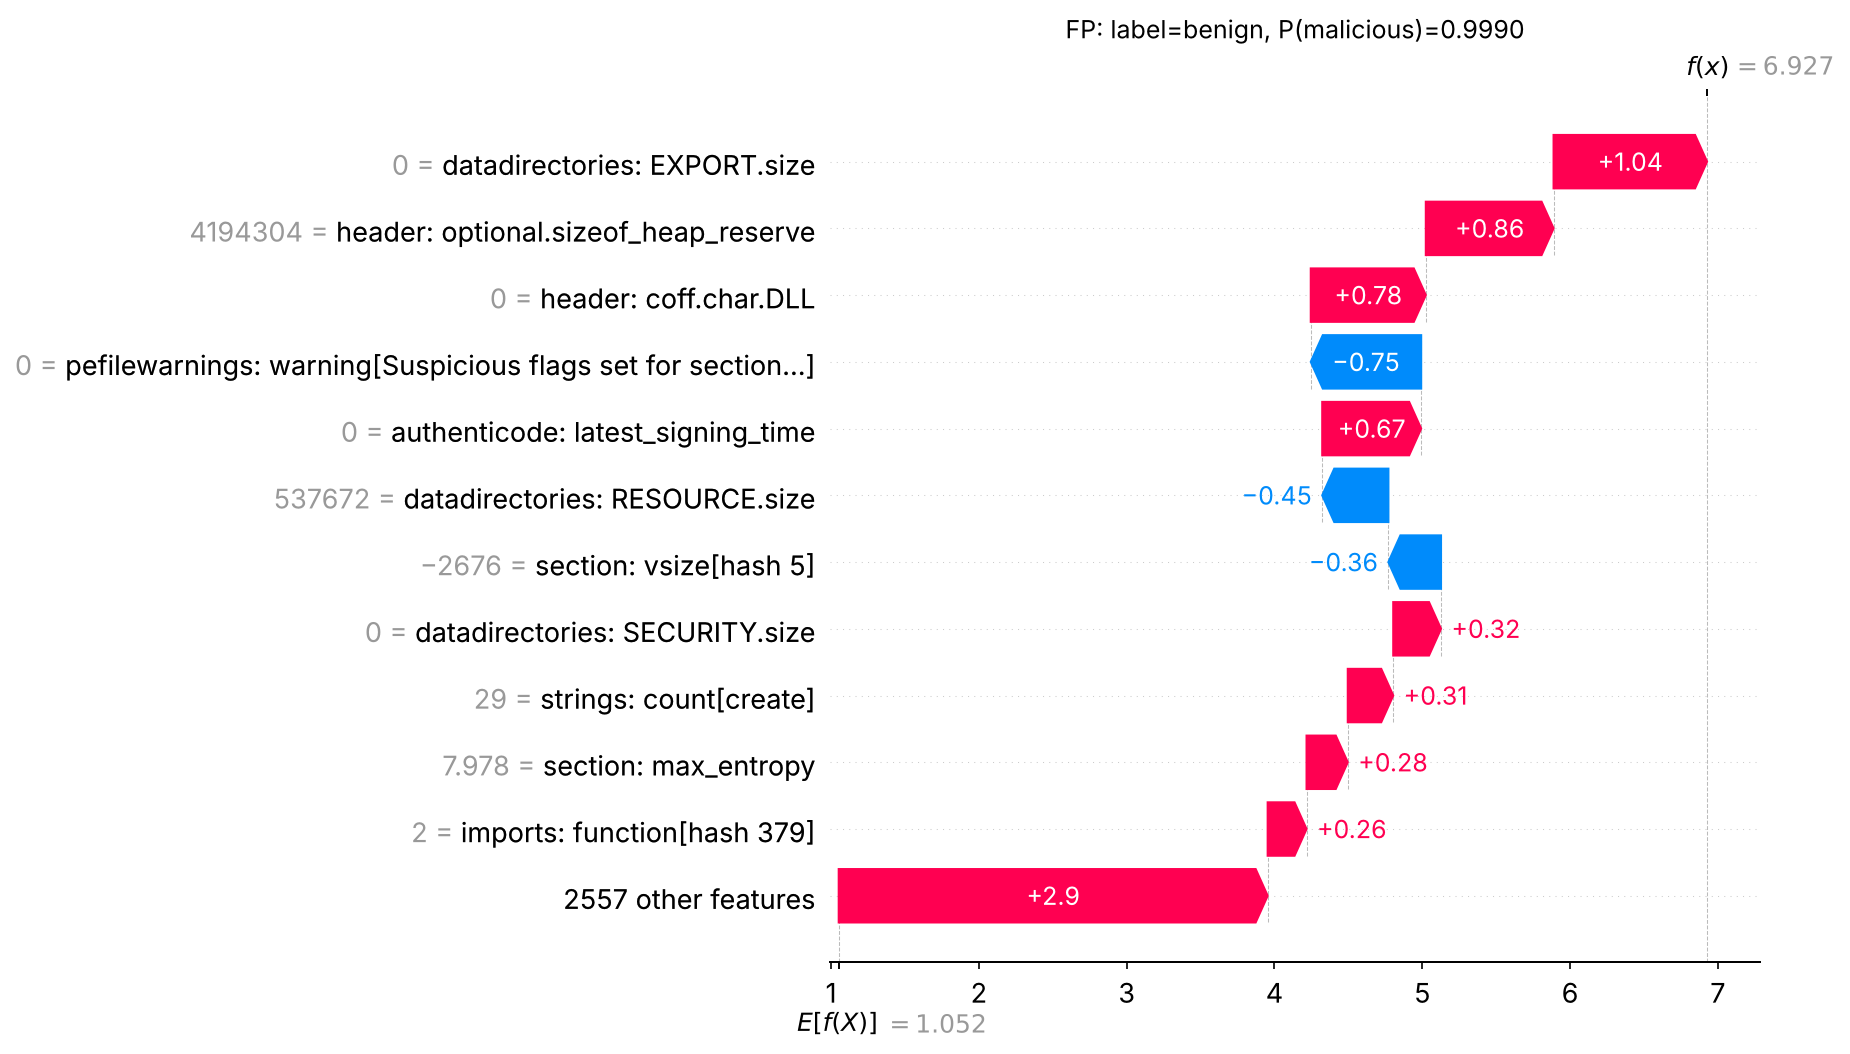

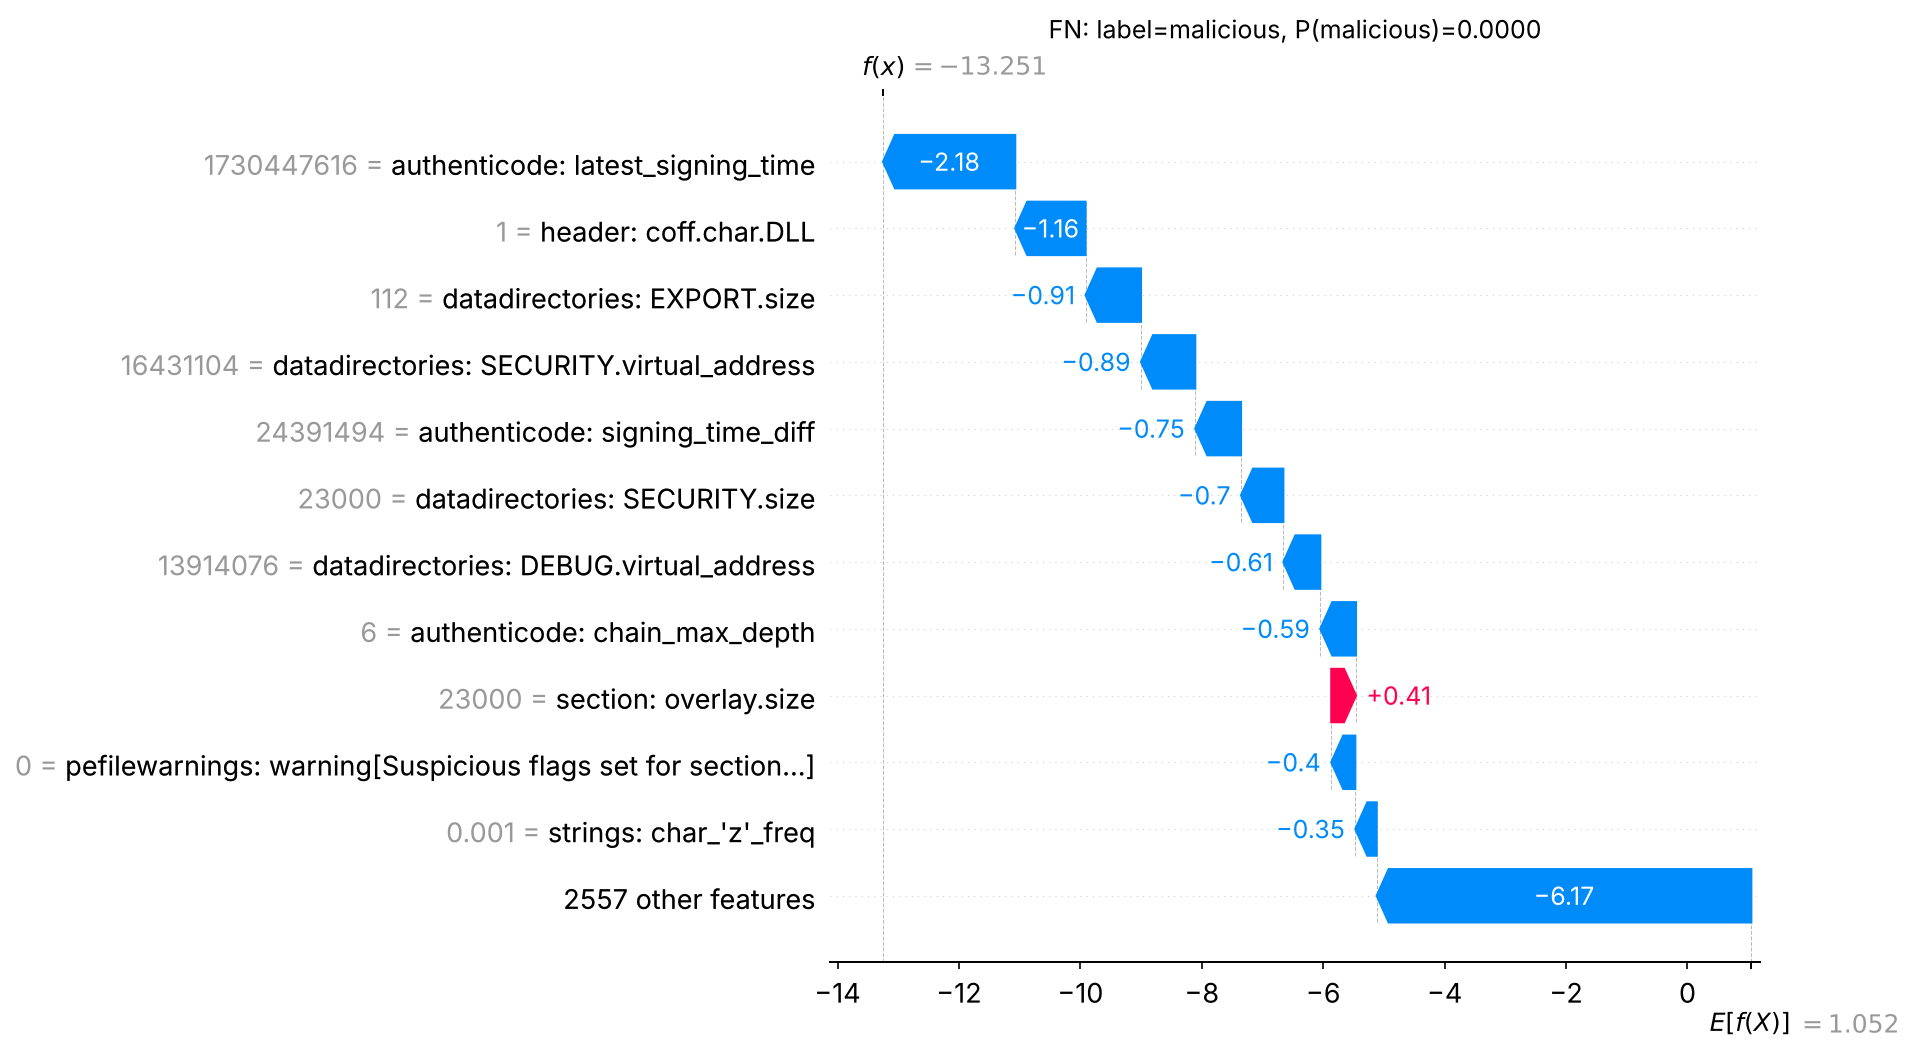

In [19]:
for case in ["tp", "fp", "fn"]:
    figure(f"shap_waterfall_{case}")

## 8. Calibration and the cost-sensitive threshold

A calibrated model's score of 0.8 means "malicious 80% of the time". Brier score and ECE measure
how far off the scores are (lower is better).

In [20]:
table("calibration")[["model", "test_set", "brier", "brier_ci_low", "brier_ci_high", "log_loss", "ece"]]

,model,test_set,brier,brier_ci_low,brier_ci_high,log_loss,ece
0,lgbm_tuned,test_future,0.013248,0.012328,0.014193,0.058718,0.008502
1,flaml,test_future,0.015960,0.015007,0.016866,0.057570,0.004082
2,autogluon,test_future,0.012938,0.012072,0.013793,0.052195,0.005645
3,h2o,test_future,0.017293,0.016369,0.018274,0.063494,0.006202
4,logreg,test_future,0.069980,0.067689,0.072147,0.622698,0.051345
5,lgbm_tuned+isotonic,test_future,0.012899,0.012111,0.013702,0.048443,0.003727
6,lgbm_tuned+platt,test_future,0.012854,0.012049,0.013659,0.048474,0.002954
7,lgbm_tuned (train OOF),train_oof,0.010922,NaN,NaN,0.050180,0.007984


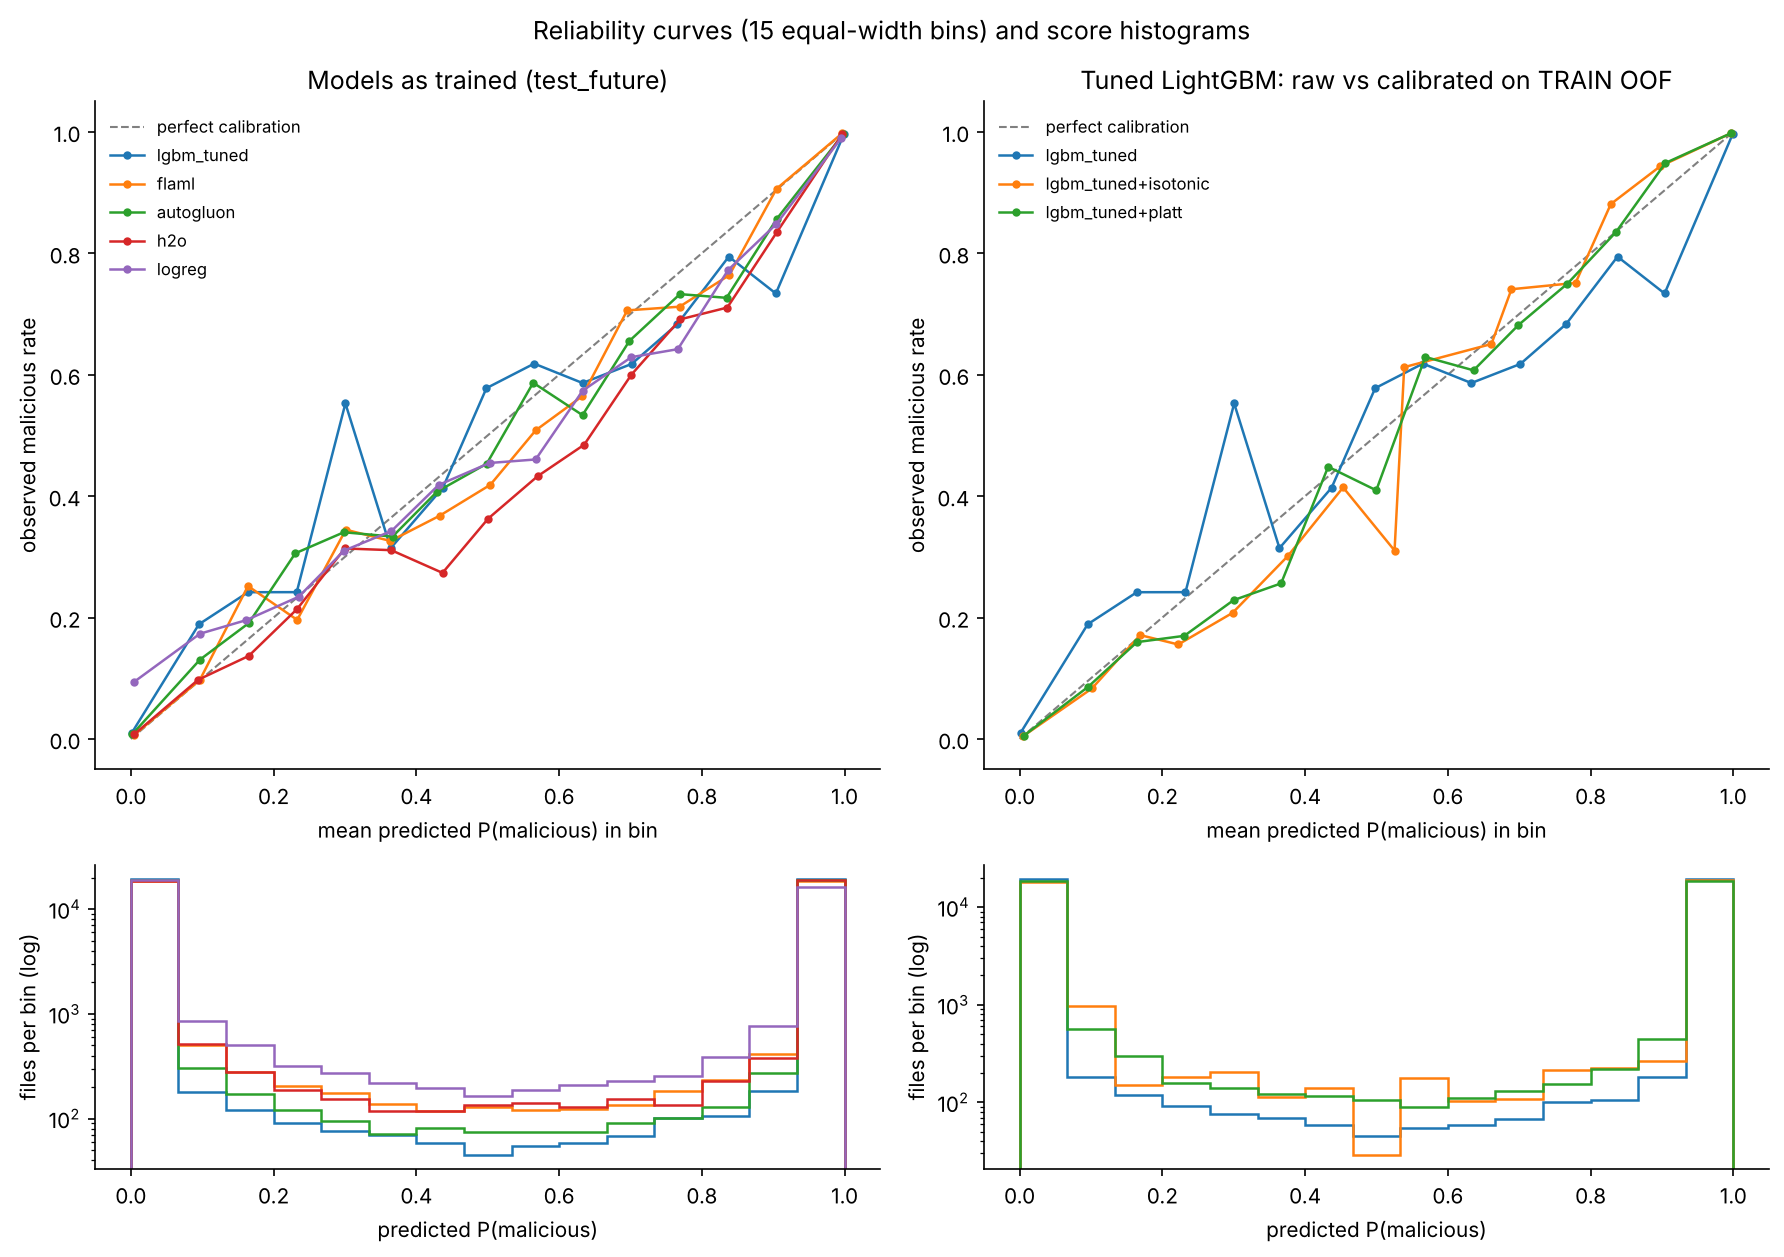

In [21]:
figure("calibration")

Missing a malware file usually costs more than a false alarm. For each cost ratio C_FN : C_FP the
threshold that minimises the total cost on `train` out-of-fold scores is chosen first, and only then
checked on test_future. The deployed app uses the threshold saved in `models/threshold.json`.

In [22]:
table("threshold")[["cost_ratio", "threshold", "oof_cost_per_1000", "test_future_precision",
                    "test_future_recall", "test_future_fpr", "test_future_cost_per_1000",
                    "test_future_cost_per_1000_at_0.5"]]

,cost_ratio,threshold,oof_cost_per_1000,test_future_precision,test_future_recall,test_future_fpr,test_future_cost_per_1000,test_future_cost_per_1000_at_0.5
0,1.0,0.429043,13.18125,0.985209,0.982353,0.014752,16.200,16.125
1,5.0,0.038401,32.23750,0.958349,0.991551,0.043106,42.675,54.225
2,10.0,0.006865,46.85000,0.930528,0.995051,0.074311,61.900,101.850
3,50.0,0.000805,104.64375,0.875104,0.997250,0.142371,139.925,482.850


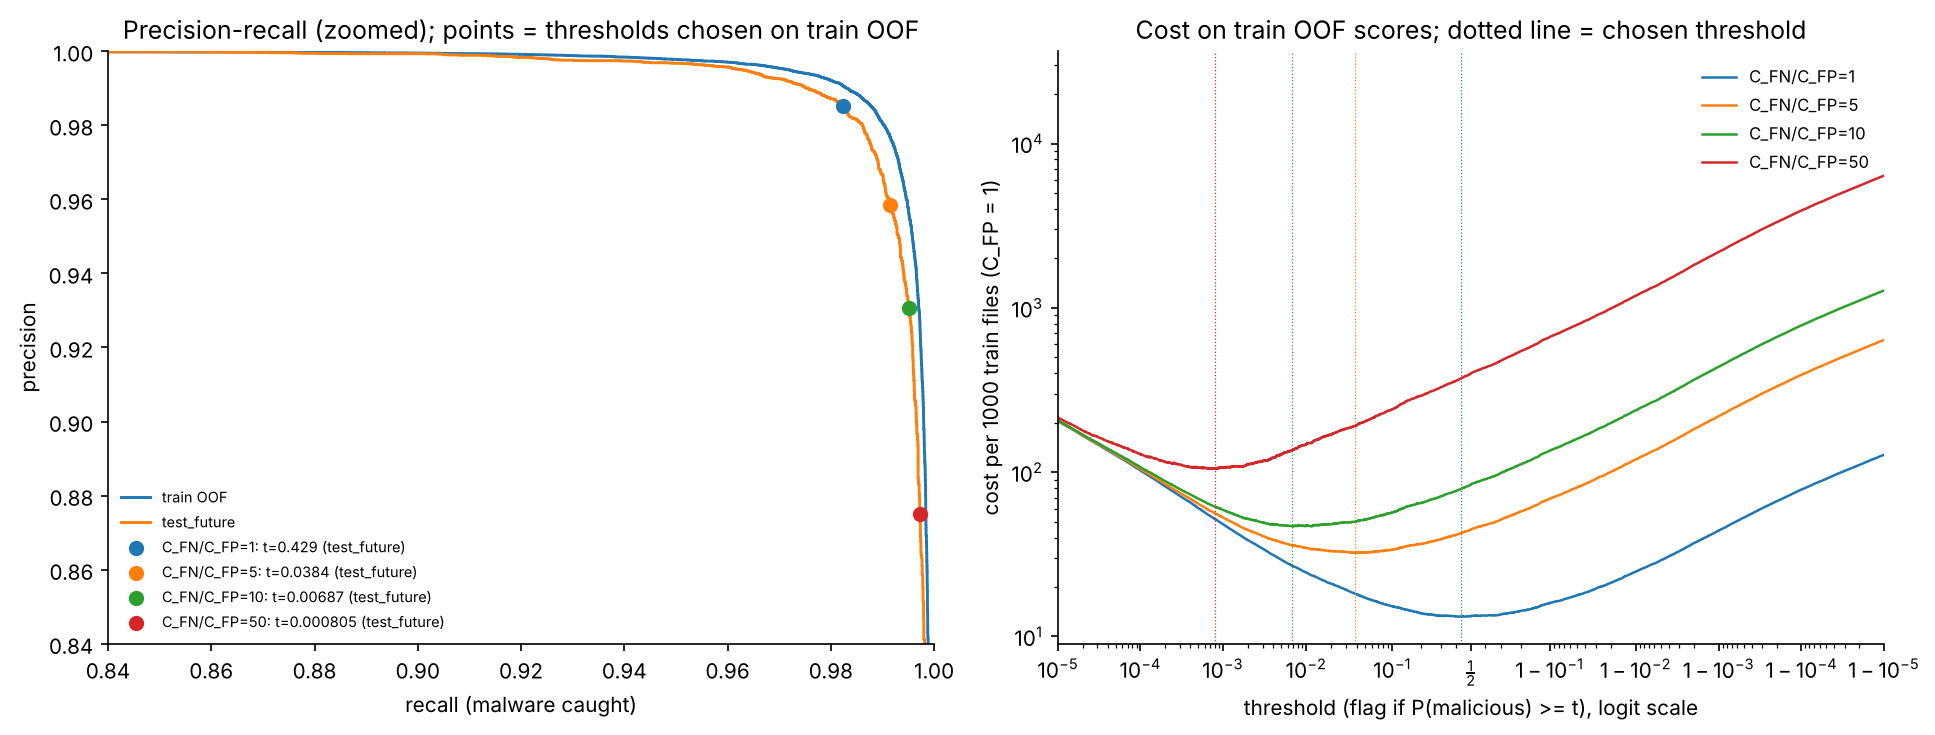

{'threshold': 0.006865195909782736,
 'cost_ratio_fn_to_fp': 10.0,
 'model': 'models/lgbm_optuna.txt',
 'how_chosen': 'minimises C_FN*FN + C_FP*FP over every distinct score on TRAIN out-of-fold predictions (persisted 3-fold CV of the train split, data/splits/cv_fold_ids; tuned params, fixed 609 rounds as the refit); cut placed midway to the next lower score. No test set was used.',
 'caveat': 'classes are 50/50 by construction; re-derive the threshold for a deployment with another prevalence'}

In [23]:
figure("pr_cost")
deployed = json.loads((config.MODELS / f"threshold{config.RUN_SUFFIX}.json").read_text(encoding="utf-8"))
{k: deployed[k] for k in ["threshold", "cost_ratio_fn_to_fp", "model", "how_chosen", "caveat"]}

## 9. Verdict and limitations

In [24]:
section("critical_eval", "## 6. What protects")
section("critical_eval", "## 7. Verdict")

## 6. What protects, and what does not

* **A provenance review of every column, before training** (human): the only defence against `detection_ratio` in this project. It is cheap and no tool did it.
* **A temporal hold-out** (train on earlier weeks, test on later ones): it measures drift and makes a date column useless, but it cannot catch a post-hoc label proxy (section 4).
* **Thresholds and costs re-derived for the real base rate.** The 10:1 cost threshold in `models/threshold.json` (t = 0.0069), chosen on 50/50 train data, has FPR 7.43% on test_future and precision 11.9% at 1% prevalence (`reports/tables/prevalence.csv`): fine on a balanced test set, costly in real traffic.
* **Class weights did not help:** 0 class-weighted refit(s) improved test_future AUC beyond the CI (`reports/tables/class_weight.csv`). With 50/50 classes there is no imbalance to correct, and reweighting only shifts scores, which a threshold does as well.
* **Calibration fitted on train out-of-fold scores carries over to later weeks:** isotonic calibration changes the test_future Brier score by -0.0003 [-0.0006, -0.0001] (`reports/tables/calibration.csv`). It makes the probabilities more trustworthy, not the ranking.
* **Retraining on recent weeks only did not help at this horizon:** 0.9973 vs 0.9981 test_future AUC (`reports/tables/drift.csv`). The real remedy, retraining with labelled files from the deployment period, cannot be tested without using test_future for training.
* **A stress set of hard files** (the challenge set) is what showed the largest real-world weakness; neither random nor temporal splits of ordinary data show it.


## 7. Verdict

For a tree model on EMBER2024 Win64, a random split overstates the ranking quality only a little (AUC 0.9991 vs 0.9981 on later weeks). The bigger overstatement comes from reading a 50/50 test set as if it were real traffic: at 1% prevalence only 44.7%, fewer than half, of the tuned model's alarms on test_future are real, and it misses 46% of the malware that antivirus engines missed at first. The AutoML tools' Step 3 models reach test_future AUC 0.9970 to 0.9980 (tuned LightGBM 0.9981), and they lose no less to drift: none of the 3 AutoML tools has a smaller AUC gap than the tuned LightGBM; a larger one: H2O AutoML (+0.0004 [+0.0002, +0.0007]) (paired bootstrap CI of the gap difference). They do not protect against leakage: given a post-hoc label column they all use it, report a near-perfect validation score, and say nothing. The protections that worked here were human ones: asking where each column comes from, testing on later data, and checking the operating point at a realistic base rate.

In [25]:
section("limitations", "# Limitations")
for part in ["## Data and features", "## Threats from the evaluation itself", "## Compute, hardware and budgets"]:
    section("limitations", part)

# Limitations and threats to validity

Generated by `scripts/run_critical_eval.py` (`src/critical_eval_writeup.py`) from the Step 0 data checks (`reports/data_check.json`, `data/splits/splits_info.json`), `config.py` and the Step 4 tables; no number is typed by hand. The findings these limits apply to are in [`critical_eval.md`](critical_eval.md).


## Data and features

* **Static features only.** Every model sees the 2,568 thrember features in 12 groups (general, histogram, byteentropy, strings, header, section, imports, exports, datadirectories, richheader, authenticode, pefilewarnings), computed from the file's bytes and PE structure without running it. Behaviour that only shows at run time (unpacking, network traffic, injected code) is invisible, and so is anything outside a Win64 PE file.
* **Packed and obfuscated files.** Packer tags in EMBER2024 exist only on malicious files, so the false-positive rate on packed *benign* software cannot be measured here; the model may simply have learned 'packed means malicious'. The feature-based proxy (whole-file entropy > 7) shows the cost: benign FPR on test_future is 2.09% for high-entropy files against 1.13% for the rest (`bias_slices.csv`, 1%-FPR train threshold).
* **Dataset age and recency.** Training files are from 2023-09-24 to 2024-09-21, test_future files from 2024-09-22 to 2024-12-14. The model has never seen anything newer, and the drift measured over 12 weeks says little about drift over the years between the data and any use of this model today.
* **Drift horizon.** All temporal results cover 12 future weeks. The weekly AUC slope (-0.00011 per week, `drift.csv`) comes with week-level CIs that overlap between the first (week 52) and the last (week 63) future week; a longer horizon could show more decay.
* **50/50 balance vs real prevalence.** The splits were built with 50.00% / 50.01% / 50.01% malware in train / test_random / test_future. Real traffic is mostly benign; at 1% prevalence the tuned model's precision on test_future would be 44.7% (`precision_both_sets.csv`). The real prevalence of the place of deployment is unknown, so 1%, 5% and 10% are scenarios, not measurements.
* **Subsampling.** After deduplication the official data has 520,000 training-period and 119,993 test-period files. We used 160,000 for train and 40,000 for test_random (from the training weeks) and 40,000 for test_future, stratified by label x week; Step 2 tuned on a 60,000-row subset with 3 folds. Larger samples would narrow the CIs, and could change close rankings between tuners and tools.
* **Label noise from AV-derived labels.** A label is a verdict of antivirus engines: in our cache no benign file has more than 2 detections and no malicious file fewer than 5 (149 benign training-period files have at least one), so files in the ambiguous middle are not in the data at all, which makes the task easier than real triage. Labels can also be wrong in ways the engines share, and they change as engines catch up: the challenge set consists of files the engines first missed.
* **Near-duplicates.** Deduplication removes exact copies only (same sha256); variants of one malware family remain on both sides of the random split, which is part of why test_random is easy (per-family slices in `bias_slices.csv`).
* **The duplicate rows in the raw data.** Each weekly file lists every sample twice (520,000 and 120,000 in-file duplicates in the training and test periods, plus 7 across test files). We deduplicate globally by sha256 before any split; without that, a random split would put copies of the same file into train and test and inflate test_random further. Anyone comparing with other EMBER2024 results should check whether they did the same.


## Threats from the evaluation itself

* **Adversarial evasion was not tested.** Static features can be changed without changing behaviour (appended bytes, added imports or sections, a valid signature). The models lean on signature columns (`explainability.md`); detection of signed malware on test_future is 83.71% at the train 1%-FPR threshold, against 98.64% for unsigned malware, and the challenge set is detected at 53.7%. An attacker who knows this has an easy target.
* **One seed (42), one split per scheme.** The CIs cover test-set sampling only, not training randomness or another draw of the splits; time-budgeted AutoML searches are not repeatable, so deltas of about 1e-4 AUC between AutoML runs are within run-to-run variation.
* **Many slices, no multiple-comparison correction.** Slice CIs are per slice; with dozens of slices some differences will look significant by chance. A test_random week has only about 385 benign files, so a single week's FPR there is very noisy.
* **Thresholds and calibrators come from smaller models.** They are fitted on train out-of-fold scores of fold models trained on two thirds of train, while the deployed model is trained on all of it (stated, not corrected; `threshold.csv` shows the effect at high cost ratios, where the test_future FPR is above the out-of-fold FPR).
* **The forward CV confounds recency with training-set size:** later folds are both closer in time and trained on more weeks. A size-matched control exists only for drift (`drift.csv`).
* **The AutoGluon leakage predictors were deleted** after scoring (about 2 GB each, little disk on the VM); their leaderboards, importances and test scores are saved, but those rows can be re-scored only by re-running them.
* **The challenge set is small and malicious only:** 814 Win64 files, so it measures misses, not false alarms.


## Compute, hardware and budgets

* **CPU only, and two machines.** Steps 2-3 ran on a 16-core Intel Core Ultra 9 285H laptop (63 GB RAM, Windows) with 16 threads; Step 4 on a cloud VM (Intel(R) Xeon(R) Processor @ 2.10GHz, 4 logical CPUs, 15.7 GB RAM, Linux 6.18.44-fc-v185). Every comparison inside a step ran on one machine with the same settings, but times are not comparable across steps, and an AutoML tool searches fewer configurations per second on the VM. The challenge-set scoring alone was re-run on a 16-CPU Windows machine (the laptop), which holds every saved Step 2-3 model including AutoGluon's; scoring fits nothing, so the hardware does not change its result.
* **Memory forced runner changes on the VM.** The runner settings were the same for every leakage variant: a lean FLAML preprocessing and a smaller H2O heap without XGBoost. AutoGluon itself skipped memory-heavy models (only in the detection_ratio run; in the clean and date runs its first LightGBM used the whole budget), so on the VM it was in effect a single LightGBM model (per-run counts in `leakage.md`).
* **The 600 s leakage budget** is a stated deviation from the 1200 s of Step 3, to keep nine AutoML runs within a few hours. The clean reruns used the same budget and hardware, so each with/without-leak pair is equal-budget (not equal-compute: see below), but the clean scores are not the Step 3 scores (H2O: test_future AUC 0.9922 at 600 s on the VM vs 0.9970 at 1200 s on the laptop). Budgets are not hard limits: the AutoML runs ended -194 s to +421 s from their budget (wall minus budget, `leakage.csv`): the budget caps the search, and FLAML's final refit and H2O's data import, ensemble and scoring come on top, so the effective compute of one tool's variants differed by minutes (`leakage.md`, *Run times*).
* **Default AutoML settings.** We tested what a user gets by default (random-split validation, default presets); other settings, such as time-ordered validation, could behave differently.